# SANOS-KF: sigmoid vs legacy DLV² parametrization

A/B comparison of the DLV² parametrization on the **same data** and otherwise-identical
config — only `use_sigmoid` flips:

* **sigmoid** (`use_sigmoid=True`): `DLV² = σ(x)·(max_dlvsq−min_dlvsq)+min_dlvsq`, state `x`
  unconstrained, no clipping.
* **legacy** (`use_sigmoid=False`): `DLV² = x + min_dlvsq`, state clipped ≥ 0.

The point is to see the benefit **beyond the metrics** — the filter's internals:
1. **Boundary saturation** — how often legacy's clip-at-0 binds (info thrown away);
2. **Per-snapshot arbitrage** — count of windows whose density has negative mass;
3. **State stability** — clipped nodes stick at the floor; sigmoid stays responsive;
4. **Visuals** — mean DLV² over time, DLV² across strike, fitted IV smile vs mid.

## Imports & data

In [1]:
import os
import sys
from datetime import date

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import polars as pl

PROJECT_ROOT = "/Users/elie/Documents/GitHub/quant_data/"
for p in [
    PROJECT_ROOT,
    os.path.join(PROJECT_ROOT, "personal", "Kalman_filter_spline"),
    os.path.join(PROJECT_ROOT, "personal", "shared_functions"),
]:
    if p not in sys.path:
        sys.path.insert(0, p)
os.environ.setdefault("QUANTDATA_RAW_DATA", "/quantdata/raw")

import personal.shared_functions.unified_metrics as um
from personal.Kalman_filter_spline.surface_kalman_filters import build_iv_observations
from personal.SANOS_KF.sanos_kf import (
    SanosKFConfig,
    build_exact_grid,
    exact_solve_density,
    run_sanos_kf,
    state_to_dlvsq,
)
from quantdata.massive.client import MassiveClient

/Users/elie/Documents/GitHub/quant_data/quantdata/__init__.py:212: UserWarning: Using cache mode 'on' as specified in environment variable QUANTDATA_CACHE_MODE.


In [2]:
TICKER = "SPY"
TRADE_DATE = date(2024, 1, 3)
MIN_TRADES = 100
SIDE = "puts"  # "both" | "calls" | "puts"
REJECT_TOL = 0.02  # |negative mass| beyond this = an "arb" snapshot

_SIDE_KW = {"calls": dict(calls_only=True), "puts": dict(puts_only=True), "both": {}}

# Otherwise-identical config; only use_sigmoid flips between the two runs.
BASE = dict(
    n_anchors=300,
    k_min=-0.60,
    k_max=0.10,
    correlated=True,
    batch_seconds=1.0,
    Sigma_init=0.04,
    Q_scale_dlv=1.0,
    P0_scale=0.1,
    max_dlvsq=4.0,
    ell=3.0,
    smoothing=False,  # intrinsic exact-solve isolates the density (no observation blur)
)

In [3]:
df_tickers = pl.read_csv(os.path.join(PROJECT_ROOT, "personal", "spy_options_tickers.csv"))
df_spy = MassiveClient().fetch_trades(TICKER, TRADE_DATE)
df_quotes, df_trades = build_iv_observations(df_tickers, TRADE_DATE, df_spy, min_trades=MIN_TRADES)
print(f"quotes: {len(df_quotes):,}  trades: {len(df_trades):,}")

Skipping O:SPY240105C00481000: 46 bad quotes
Skipping O:SPY240105C00482000: 64 bad quotes
Skipping O:SPY240105C00483000: 842 bad quotes
Skipping O:SPY240105C00484000: 2129 bad quotes
Skipping O:SPY240105C00485000: 3888 bad quotes
Skipping O:SPY240105P00462500: 17 bad quotes
Expiry 2024-01-05: implied forward from 13 strike(s)
quotes: 2,115,510  trades: 74,099


## Run-one-variant helper

Runs one parametrization and gathers state → DLV² (via `state_to_dlvsq`, so both land on the
same axis), per-window density / negative mass, the fitted smile, and the metrics.

In [4]:
def run_variant(use_sigmoid: bool, x_init=None):
    cfg = SanosKFConfig(use_sigmoid=use_sigmoid, **BASE, **_SIDE_KW[SIDE])
    q, _, st = run_sanos_kf(df_quotes, df_trades, cfg, return_state=True, x_init=x_init)
    bs_ns = int(cfg.batch_seconds * 1e9)

    # quotes -> last-per-(window,strike,is_call), prices in native undiscounted dollars
    qb = q.to_pandas()
    qb["window"] = qb["ts_ns"].astype("int64") // bs_ns
    qb = (
        qb.sort_values("ts_ns")
        .drop_duplicates(["window", "strike", "is_call"], keep="last")
        .dropna(subset=["sanos_kf_price_prior"])
    )
    F = qb["forward"].to_numpy(float)
    K = qb["strike"].to_numpy(float)
    ic = qb["is_call"].to_numpy(bool)
    dfac = qb["discount_factor"].to_numpy(float) if "discount_factor" in qb else np.ones(len(qb))
    to_native = lambda c: np.where(ic, c, c - (F - K))  # noqa: E731
    df_eval = um.from_option_prices(
        ts=qb["window"].to_numpy(),
        strike=K,
        forward=F,
        is_call=ic,
        bid=qb["bid_price"].to_numpy(float),
        ask=qb["ask_price"].to_numpy(float),
        prior_price=to_native(qb["sanos_kf_price_prior"].to_numpy(float) * F),
        post_price=to_native(qb["sanos_kf_price"].to_numpy(float) * F),
        discount_factor=dfac,
    )

    # state history -> net DLV² (same units for both variants)
    grid_K, tte_ref = build_exact_grid(df_quotes, cfg)
    F0 = float(np.nanmedian(df_quotes["forward"].to_numpy().astype(float)))
    stp = st.to_pandas()
    stp["window"] = stp["ts_ns"].astype("int64") // bs_ns
    stp = stp.sort_values("ts_ns").drop_duplicates("window", keep="last")
    xcols = [c for c in stp.columns if c.startswith("x_")]
    x_mat = stp[xcols].to_numpy(float)  # (W, n_nodes) raw state (logit if sigmoid else DLV²)
    dlvsq = state_to_dlvsq(x_mat, cfg)  # (W, n_nodes) net DLV²

    # per-window density + signed negative mass (on the model's own density)
    neg = []
    for xr in x_mat:
        d = exact_solve_density(
            xr, grid_K, tte_ref, cfg.min_dlvsq, cfg.max_dlvsq, fwd=F0, use_sigmoid=use_sigmoid
        )
        neg.append(np.nan if d is None else float(np.minimum(d, 0.0).sum()))
    neg = np.array(neg)
    m = um.evaluate(df_eval, model_name="x", neg_mass_values=neg.copy())

    floor = cfg.min_dlvsq
    at_floor = dlvsq <= floor + 1e-9
    return dict(
        cfg=cfg,
        grid_K=grid_K,
        dlvsq=dlvsq,
        neg=neg,
        metrics=m,
        qb=qb,
        x_end=x_mat[-1],  # end-of-day RAW posterior state (feed as next-day x_init)
        sat_frac=float(at_floor.mean()),
        node_stick=float((np.diff(dlvsq, axis=0) == 0.0).mean()),
        arb_frac=float(np.mean(neg < -REJECT_TOL)),
    )

In [5]:
sig = run_variant(True)
leg = run_variant(False)
print("done")

done


## Non-metric diagnostics

In [6]:
diag = pd.DataFrame(
    {
        "sigmoid": {
            "state pinned at DLV² floor": sig["sat_frac"],
            "frozen state steps (node·window)": sig["node_stick"],
            "arb snapshots (|negmass|>tol)": sig["arb_frac"],
            "mean |negative mass|": -np.nanmean(np.minimum(sig["neg"], 0)),
            "ho_nse_med": sig["metrics"].get("ho_nse_med", np.nan),
            "ho_nse_mean": sig["metrics"].get("ho_nse_mean", np.nan),
            "is_nse_med": sig["metrics"].get("is_nse_med", np.nan),
        },
        "legacy": {
            "state pinned at DLV² floor": leg["sat_frac"],
            "frozen state steps (node·window)": leg["node_stick"],
            "arb snapshots (|negmass|>tol)": leg["arb_frac"],
            "mean |negative mass|": -np.nanmean(np.minimum(leg["neg"], 0)),
            "ho_nse_med": leg["metrics"].get("ho_nse_med", np.nan),
            "ho_nse_mean": leg["metrics"].get("ho_nse_mean", np.nan),
            "is_nse_med": leg["metrics"].get("is_nse_med", np.nan),
        },
    }
)
diag

,sigmoid,legacy
state pinned at DLV² floor,0.000000,1.043206e-03
frozen state steps (node·window),0.006892,7.259822e-03
arb snapshots (|negmass|>tol),0.000000,0.000000e+00
mean |negative mass|,-0.000000,1.073778e-18
ho_nse_med,0.441609,5.353458e-01
ho_nse_mean,0.539351,6.680422e-01
is_nse_med,0.347291,2.732489e-01


## Visual comparison

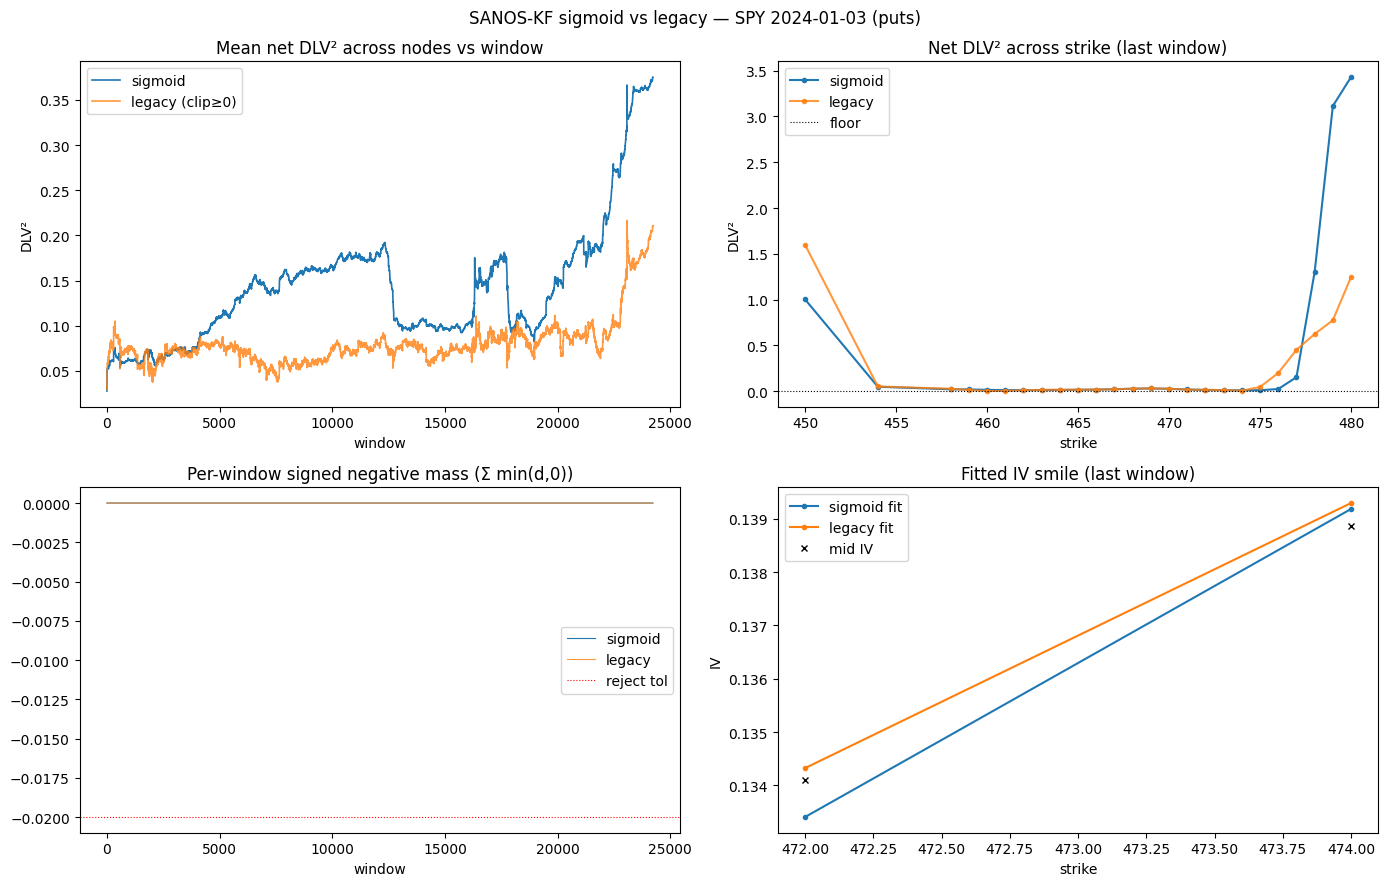

In [7]:
fig, ax = plt.subplots(2, 2, figsize=(14, 9))

# (1) mean DLV² across nodes over time
ax[0, 0].plot(sig["dlvsq"].mean(1), label="sigmoid", lw=1.2)
ax[0, 0].plot(leg["dlvsq"].mean(1), label="legacy (clip≥0)", lw=1.2, alpha=0.8)
ax[0, 0].set(title="Mean net DLV² across nodes vs window", xlabel="window", ylabel="DLV²")
ax[0, 0].legend()

# (2) DLV² across strike at the last window
ax[0, 1].plot(sig["grid_K"][1:-1], sig["dlvsq"][-1], ".-", label="sigmoid")
ax[0, 1].plot(leg["grid_K"][1:-1], leg["dlvsq"][-1], ".-", label="legacy", alpha=0.8)
ax[0, 1].axhline(sig["cfg"].min_dlvsq, ls=":", c="k", lw=0.8, label="floor")
ax[0, 1].set(title="Net DLV² across strike (last window)", xlabel="strike", ylabel="DLV²")
ax[0, 1].legend()

# (3) per-window signed negative mass
ax[1, 0].plot(sig["neg"], label="sigmoid", lw=0.8)
ax[1, 0].plot(leg["neg"], label="legacy", lw=0.8, alpha=0.8)
ax[1, 0].axhline(-REJECT_TOL, ls=":", c="r", lw=0.8, label="reject tol")
ax[1, 0].set(title="Per-window signed negative mass (Σ min(d,0))", xlabel="window")
ax[1, 0].legend()

# (4) fitted IV smile vs mid at the last window
for tag, r, c in (("sigmoid", sig, "C0"), ("legacy", leg, "C1")):
    snap = r["qb"][r["qb"]["window"] == r["qb"]["window"].max()].sort_values("strike")
    ax[1, 1].plot(snap["strike"], snap["sanos_kf_iv"], ".-", color=c, label=f"{tag} fit")
snap = sig["qb"][sig["qb"]["window"] == sig["qb"]["window"].max()].sort_values("strike")
if "observed_iv" in snap:
    ax[1, 1].plot(snap["strike"], snap["observed_iv"], "kx", ms=4, label="mid IV")
ax[1, 1].set(title="Fitted IV smile (last window)", xlabel="strike", ylabel="IV")
ax[1, 1].legend()

fig.suptitle(f"SANOS-KF sigmoid vs legacy — {TICKER} {TRADE_DATE} ({SIDE})")
fig.tight_layout()
plt.show()

## Per-snapshot IV comparison

Set `snap_idx` to pick a 1-second window (index into the sorted windows; negative counts from
the end, e.g. `-1` = last). Shows sigmoid vs legacy fitted IV against the market mid (and the
bid/ask IV band when available) at that snapshot.

snap_idx=12216  ->  window 1704304465  (12216 of 24066)


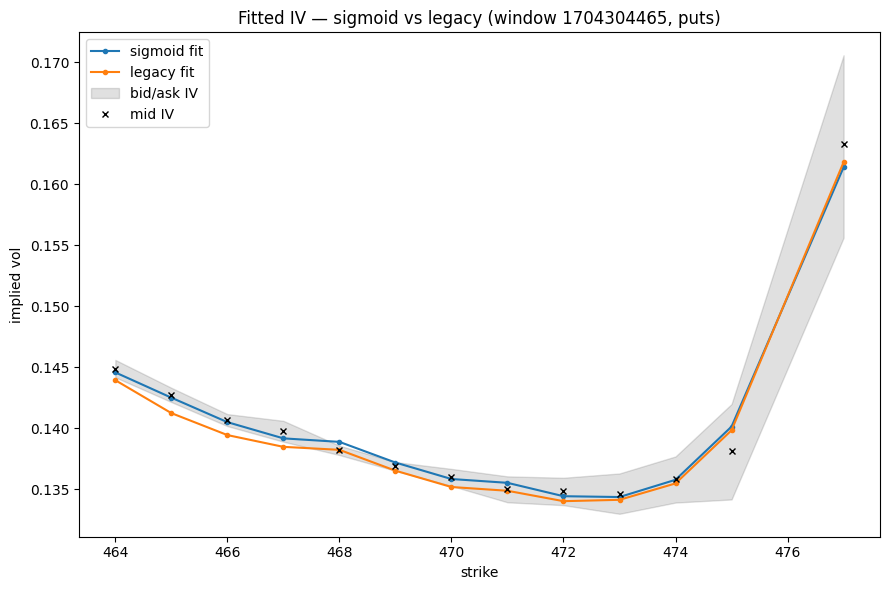

In [8]:
snap_idx = (
    sig["dlvsq"].shape[0] // 2 + 100
)  # which window to inspect: index into sorted windows (-1 = last)

# Both variants share the same windows (same data + batching); use sig's as the index.
windows = np.sort(sig["qb"]["window"].unique())
w = windows[snap_idx]
print(f"snap_idx={snap_idx}  ->  window {w}  ({snap_idx % len(windows)} of {len(windows)})")

fig, ax = plt.subplots(figsize=(9, 6))
for tag, r, c in (("sigmoid", sig, "C0"), ("legacy", leg, "C1")):
    snap = r["qb"][r["qb"]["window"] == w].sort_values("strike")
    ax.plot(snap["strike"], snap["sanos_kf_iv"], ".-", color=c, label=f"{tag} fit")

# market reference from the sigmoid run (identical quotes in both)
snap = sig["qb"][sig["qb"]["window"] == w].sort_values("strike")
if "bid_iv" in snap and "ask_iv" in snap:
    ax.fill_between(
        snap["strike"], snap["bid_iv"], snap["ask_iv"], color="k", alpha=0.12, label="bid/ask IV"
    )
if "observed_iv" in snap:
    ax.plot(snap["strike"], snap["observed_iv"], "kx", ms=5, label="mid IV")

ax.set(
    title=f"Fitted IV — sigmoid vs legacy (window {w}, {SIDE})",
    xlabel="strike",
    ylabel="implied vol",
)
ax.legend()
fig.tight_layout()
plt.show()

## Held-out NSE / RMSE / out-of-band % vs time

Same machinery as `three_model_comparison.ipynb`: for each 1-second snapshot, the **held-out**
(one-step-ahead prior) metric over that snapshot's strikes, then **medianed into 1-minute bins**
(robust to outliers), shown faint (raw) + bold (15-min centered rolling median). All in call-price
space `C/df` (puts PCP-converted), so sigmoid and legacy are apples-to-apples.

- **NSE** = `mean(|prior − mid| / half_spread)` — error in spread units.
- **RMSE** = `sqrt(mean((prior − mid)²))` — pricing error in dollars, no spread in it.
- **out-of-band %** = `100·mean(|prior − mid| > half_spread)` — share of strikes priced outside
  the bid/ask band (inverts the spread dependence).

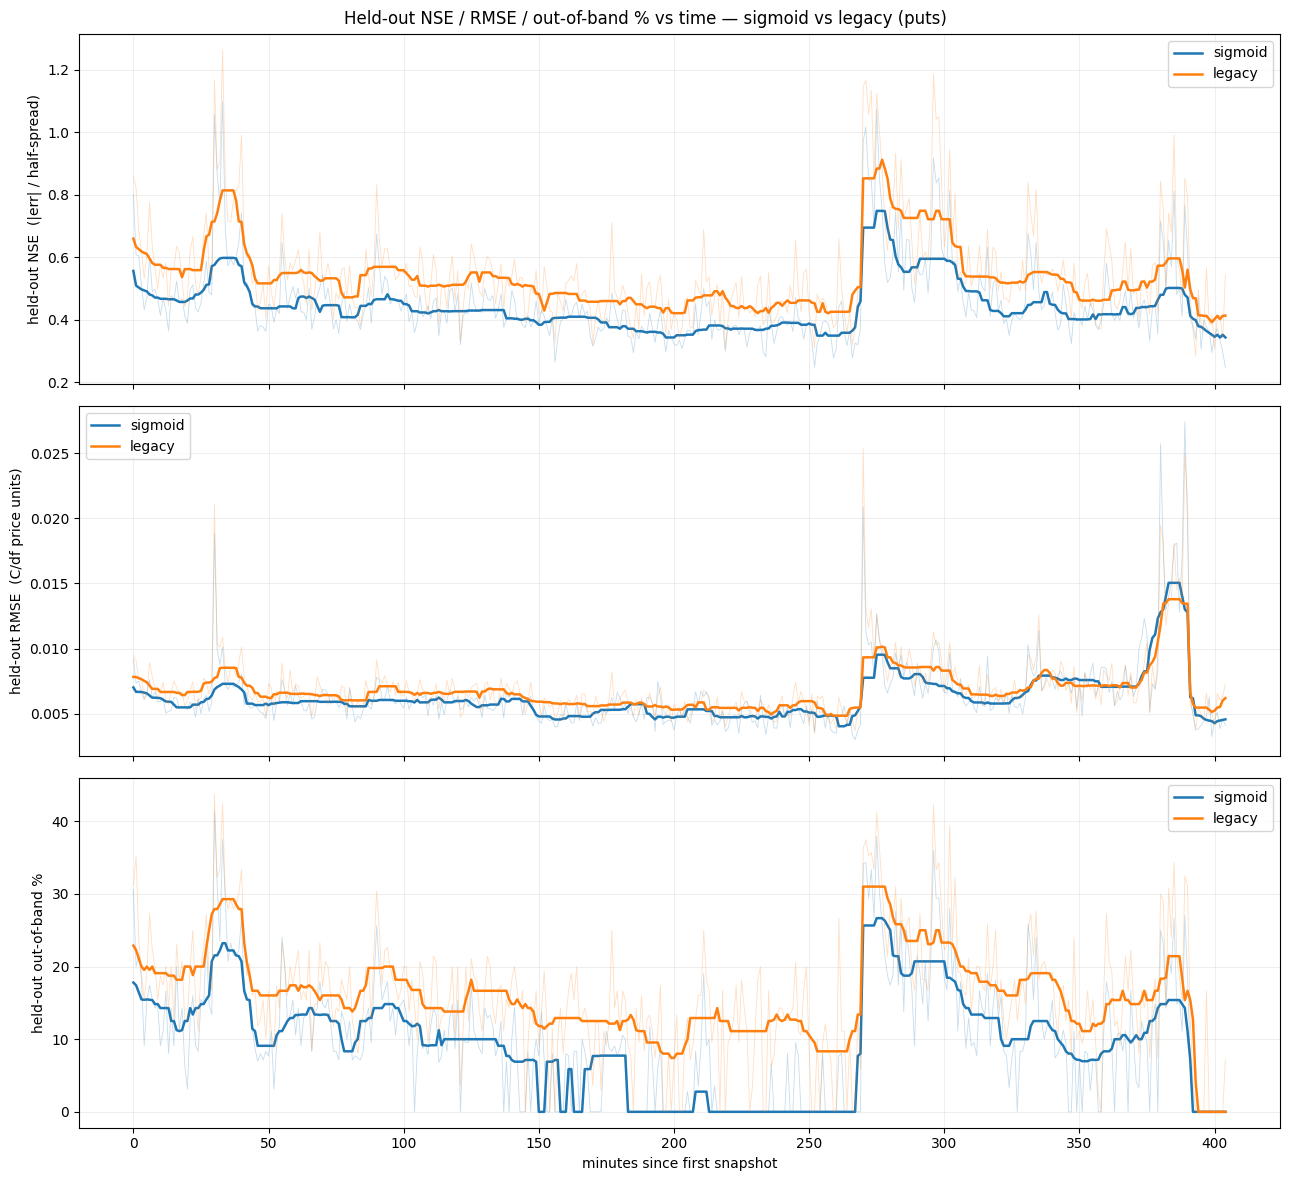

In [9]:
def eval_table(qb):
    """Standard eval table (one row per ts,strike) in call-price space C/df. ts = the
    1-second window = ts_ns // 1e9 = epoch seconds, so all models share the same axis."""
    F = qb["forward"].to_numpy(float)
    K = qb["strike"].to_numpy(float)
    ic = qb["is_call"].to_numpy(bool)
    dfac = qb["discount_factor"].to_numpy(float) if "discount_factor" in qb else np.ones(len(qb))
    dfac = np.where(np.isfinite(dfac) & (dfac > 0), dfac, 1.0)
    bid = qb["bid_price"].to_numpy(float)
    ask = qb["ask_price"].to_numpy(float)
    to_call = lambda p: np.where(
        ic, p, p + F - K
    )  # native undiscounted -> call space (PCP)  # noqa: E731
    return pd.DataFrame(
        {
            "ts": qb["window"].to_numpy(),
            "strike": K,
            "mid_call": to_call(0.5 * (bid + ask) / dfac),
            "half_spread": np.maximum(0.5 * (ask - bid) / dfac, 1e-10),
            "prior_call": qb["sanos_kf_price_prior"].to_numpy(float) * F,
            "post_call": qb["sanos_kf_price"].to_numpy(float) * F,
        }
    ).drop_duplicates(subset=["ts", "strike"], keep="last")


eval_tables = {"sigmoid": eval_table(sig["qb"]), "legacy": eval_table(leg["qb"])}
t0 = min(int(t["ts"].min()) for t in eval_tables.values())


def per_snapshot_metric(tbl, kind):
    """Per-snapshot HELD-OUT (prior) metric as a ts-indexed Series:
    'nse'  -> mean(|prior - mid| / half_spread)
    'rmse' -> sqrt(mean((prior - mid)^2))                  [C/df price units]
    'out'  -> 100 * mean(|prior - mid| > half_spread)      [% strikes outside band]"""
    prior = tbl["prior_call"].to_numpy(float)
    mid = tbl["mid_call"].to_numpy(float)
    hs = tbl["half_spread"].to_numpy(float)
    hs = np.where(np.isfinite(hs) & (hs > 0), hs, np.nan)
    mask = np.isfinite(prior) & np.isfinite(mid) & np.isfinite(hs)
    err = prior - mid
    if kind == "nse":
        col = np.where(mask, np.abs(err) / hs, np.nan)
        return pd.Series(col, index=tbl["ts"].to_numpy()).groupby(level=0).mean().dropna()
    if kind == "rmse":
        col = np.where(mask, err**2, np.nan)
        return np.sqrt(pd.Series(col, index=tbl["ts"].to_numpy()).groupby(level=0).mean().dropna())
    if kind == "out":
        col = np.where(mask, (np.abs(err) > hs).astype(float), np.nan)
        return pd.Series(col, index=tbl["ts"].to_numpy()).groupby(level=0).mean().dropna() * 100.0
    raise ValueError(f"unknown kind {kind!r}")


def per_minute(s):
    """Median per-snapshot value within each 1-minute bin -> (minutes-since-t0, values)."""
    minute = (s.index.to_numpy(np.int64) - t0) // 60
    g = pd.Series(s.to_numpy(), index=minute).groupby(level=0).median()
    return g.index.to_numpy(float), g.to_numpy(float)


def smooth(v, w=15):
    """Centered rolling median over w minutes — the trend through the intraday noise."""
    return pd.Series(v).rolling(w, min_periods=max(3, w // 3), center=True).median().to_numpy()


metrics = [
    ("nse", "held-out NSE  (|err| / half-spread)"),
    ("rmse", "held-out RMSE  (C/df price units)"),
    ("out", "held-out out-of-band %"),
]
fig, axes = plt.subplots(len(metrics), 1, figsize=(13, 12), sharex=True)
for ax, (kind, ylabel) in zip(axes, metrics):
    for name, tbl in eval_tables.items():
        mins, val = per_minute(per_snapshot_metric(tbl, kind))
        (line,) = ax.plot(mins, val, lw=0.6, alpha=0.25)
        ax.plot(mins, smooth(val), lw=1.8, color=line.get_color(), label=name)
    ax.set_ylabel(ylabel)
    ax.grid(alpha=0.2)
    ax.legend()
axes[-1].set_xlabel("minutes since first snapshot")
fig.suptitle(f"Held-out NSE / RMSE / out-of-band % vs time — sigmoid vs legacy ({SIDE})")
fig.tight_layout()
plt.show()

## Warm-start: carry end-of-day state into the next day

Real use: keep each model's **end-of-day posterior state** (the learned DLV² surface) and use it as
the **initial state** for the next day, instead of the flat `Sigma_init`. There's no next day here,
so as a stand-in we re-run on the **same day** warm-started from that state — the question is whether
carrying the surface shortens the morning warm-up (lower / faster-converging held-out NSE early on).

Only the state **mean** is carried (`x_init`); the covariance `P` still resets to `P0`, so the filter
remains free to adapt — it just starts from a sensible surface rather than flat. (A true cross-day
warm-start would also carry `P`, but the grid must match, which it does on a same-day re-run.)

,sigmoid,legacy
ho_nse_med cold,0.441609,0.535346
ho_nse_med warm,0.441139,0.535682
ho_nse_mean cold,0.539351,0.668042
ho_nse_mean warm,0.538263,0.665640


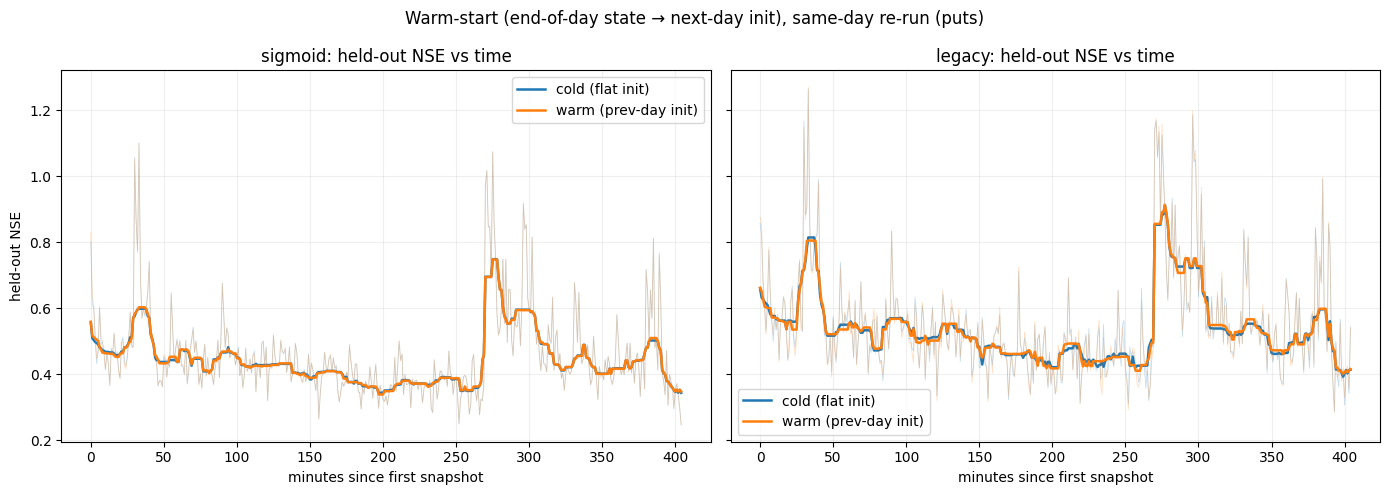

In [10]:
# Re-run each variant warm-started from its OWN cold end-of-day state.
sig_warm = run_variant(True, x_init=sig["x_end"])
leg_warm = run_variant(False, x_init=leg["x_end"])

runs = {"sigmoid": (sig, sig_warm), "legacy": (leg, leg_warm)}

# cold vs warm metrics
warm_tbl = pd.DataFrame(
    {
        name: {
            "ho_nse_med cold": cold["metrics"].get("ho_nse_med", np.nan),
            "ho_nse_med warm": warm["metrics"].get("ho_nse_med", np.nan),
            "ho_nse_mean cold": cold["metrics"].get("ho_nse_mean", np.nan),
            "ho_nse_mean warm": warm["metrics"].get("ho_nse_mean", np.nan),
        }
        for name, (cold, warm) in runs.items()
    }
)
display(warm_tbl)

# held-out NSE vs time — cold vs warm, one panel per parametrization (warm-up shows early)
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
for ax, (name, (cold, warm)) in zip(axes, runs.items()):
    for tag, r in (("cold (flat init)", cold), ("warm (prev-day init)", warm)):
        mins, val = per_minute(per_snapshot_metric(eval_table(r["qb"]), "nse"))
        (line,) = ax.plot(mins, val, lw=0.6, alpha=0.25)
        ax.plot(mins, smooth(val), lw=1.8, color=line.get_color(), label=tag)
    ax.set(title=f"{name}: held-out NSE vs time", xlabel="minutes since first snapshot")
    ax.grid(alpha=0.2)
    ax.legend()
axes[0].set_ylabel("held-out NSE")
fig.suptitle(f"Warm-start (end-of-day state → next-day init), same-day re-run ({SIDE})")
fig.tight_layout()
plt.show()